# ZeRO, DeepSpeed and large-scale training

**TL;DR.** In the previous notebook (`01_ddp_vs_fsdp`) we saw that DDP replicates 16 bytes per parameter on every GPU and that FSDP shards it. ZeRO (*Zero Redundancy Optimizer*; Rajbhandari et al., 2020) is the same idea cut into three independent stages, and the stages have very different costs: sharding the optimizer state (stage 1) and the gradients (stage 2) **adds no communication over DDP** (2Ψ per step), and only sharding the parameters (stage 3, which is FSDP) costs **1.5×** (3Ψ). For the 7.5B-parameter model in the ZeRO paper on 64 GPUs, per-GPU model state falls from **120 GB** (DDP) to **31.4 GB**, **16.6 GB** and **1.9 GB** for stages 1, 2 and 3. We reproduce those four numbers from our own accounting and check the mechanics of every stage against single-process training (final weights agree to ~2e-7).

Sharding fixes *model state* only. At large scale three more things bind: **activations** (fixed by recomputation, which costs ~33% extra compute), **batch size per GPU** (fixed by gradient accumulation), and **models whose single layers are too big or too slow** (fixed by tensor and pipeline parallelism, with their own costs: communication per layer and idle "bubbles"). We build each of these from scratch on small tensors, then put them together in a configuration search for a 64-billion-parameter model on 64 GPUs.

| section | what we do | key number |
|---|---|---|
| 1 | Three redundancies | 120 → 31.4 → 16.6 → 1.9 GB (7.5B, N = 64) |
| 2 | ZeRO-1: shard the optimizer state | same 2Ψ communication as DDP |
| 3 | ZeRO-2: shard the gradients | same 2Ψ communication, lower peak |
| 4 | ZeRO-3: shard the parameters | 3Ψ communication, lowest memory |
| 5 | DeepSpeed in practice | config for each stage, offload cost (modelled) |
| 6 | Activations and batch size | recomputation: ~⅓ more compute, large memory cut |
| 7 | Tensor parallelism | one all-reduce per MLP block, exact match to dense |
| 8 | Pipeline parallelism | bubble = (p−1)/(m+p−1), measured by simulation |
| 9 | Combining them | a configuration search for 64B on 64 GPUs |

*Scale, stated plainly:* sections 2–4 and 6–8 are measured on tiny models on a Mac CPU (simulated ranks, real tensors). Sections 1, 5 and 9 use arithmetic and assumed hardware constants and are labelled **modelled**. DeepSpeed itself is not installed here and is not run. Prerequisite: `01_ddp_vs_fsdp`.

In [1]:
import io, math, time, json, inspect, itertools
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as Fn
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image as PILImage
from IPython.display import Image, display
from torch.utils.checkpoint import checkpoint
import dist_kit as dk

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
ASSETS = Path("../../assets/distributed").resolve(); ASSETS.mkdir(parents=True, exist_ok=True)
COL = {"params": "#1c7ed6", "grads": "#2f9e44", "optimizer": "#7048e8", "gathered params": "#e8590c", "gathered grads": "#c92a2a"}
CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail)); print(("PASS" if ok else "FAIL"), "-", name, ("| " + detail) if detail else "")
N, LR, STEPS = 4, 1e-2, 5
xs, ys, X, Y = dk.make_data(N)
PSI = dk.nparams(dk.make_model())
base, _ = dk.baseline_train(STEPS, LR, N)
print("torch", torch.__version__, "| toy Psi =", PSI, "| N =", N)

torch 2.15.0 | toy Psi = 9668 | N = 4


## 1. Three redundancies

**Tiny example.** One parameter, four GPUs, DDP. Every GPU stores the bf16 weight (2 B), the bf16 gradient (2 B) and 12 B of optimizer state (fp32 master, *m*, *v*): 16 B × 4 GPUs = 64 B for 16 B of information. Three quantities are each stored four times. ZeRO removes the redundancy one quantity at a time, in order of how cheap it is to do so: **stage 1** shards optimizer state (the biggest, 12 B), **stage 2** also shards gradients (2 B), **stage 3** also shards parameters (2 B).

**General definition.** Per GPU, with Ψ parameters, N data-parallel GPUs, and K = 12 optimizer bytes per parameter (Rajbhandari et al., 2020):

| stage | parameters | gradients | optimizer | total per GPU |
|---|---|---|---|---|
| 0 (DDP) | 2Ψ | 2Ψ | KΨ | (4 + K)Ψ |
| 1 (P_os) | 2Ψ | 2Ψ | KΨ/N | 4Ψ + KΨ/N |
| 2 (P_os+g) | 2Ψ | 2Ψ/N | KΨ/N | 2Ψ + (2 + K)Ψ/N |
| 3 (P_os+g+p) | 2Ψ/N | 2Ψ/N | KΨ/N | (4 + K)Ψ/N |

The helper `dk.state_bytes_per_gpu` is exactly this table. We use it for the paper's own example, a 7.5B model on 64 GPUs, and for a 70B model on 64 GPUs.

In [2]:
def gb(psi, N, stage): return dk.state_bytes_per_gpu(psi, N, stage) / 1e9
print(f"{'':20s}" + "".join(f"{s:>12s}" for s in ("DDP", "ZeRO-1", "ZeRO-2", "ZeRO-3")))
for name, psi, n in (("7.5B, N=64", 7.5e9, 64), ("70B, N=64", 70e9, 64), ("70B, N=512", 70e9, 512)):
    print(f"{name:20s}" + "".join(f"{gb(psi, n, s):10.1f} GB" for s in range(4)))
paper = [120, 31.4, 16.6, 1.9]
mine = [gb(7.5e9, 64, s) for s in range(4)]
check("reproduces the ZeRO paper's 7.5B / N=64 example: 120, 31.4, 16.6, 1.9 GB", all(abs(m - p) < 0.06 for m, p in zip(mine, paper)), str([round(m, 2) for m in mine]))
check("ZeRO-1 saving approaches 4x for large N", abs(gb(7.5e9, 10**6, 1) / gb(7.5e9, 10**6, 0) - 4 / 16) < 1e-3)

                             DDP      ZeRO-1      ZeRO-2      ZeRO-3
7.5B, N=64               120.0 GB      31.4 GB      16.6 GB       1.9 GB
70B, N=64               1120.0 GB     293.1 GB     155.3 GB      17.5 GB
70B, N=512              1120.0 GB     281.6 GB     141.9 GB       2.2 GB
PASS - reproduces the ZeRO paper's 7.5B / N=64 example: 120, 31.4, 16.6, 1.9 GB | [120.0, 31.41, 16.64, 1.88]
PASS - ZeRO-1 saving approaches 4x for large N 


Stage 1 alone gives about a **3.8× reduction** at N = 64 (120 → 31.4 GB), because the optimizer state is three quarters of the bytes; stage 2 adds a further 1.9×; stage 3 divides what is left by N. A 70B model still does not fit on 64 GPUs at stage 1 (293 GB) or stage 2 (155 GB), but does at stage 3 (17.5 GB); we return to this in Section 9. Memory is half of the question, though. The other half is what each stage costs in communication, and the answer is surprising enough that we measure it.

## 2. ZeRO-1: shard the optimizer state

**Tiny example.** Four GPUs, a gradient vector of 8 numbers, Adam state for 8 numbers. In DDP all four GPUs update all 8 weights identically (the work is repeated four times). In ZeRO-1, GPU *r* owns weights `[2r, 2r+2)` and only keeps Adam state for those. After backward each GPU has the full local gradient, but needs only the averaged gradient *of its own slice*, so we **reduce-scatter** instead of all-reduce; each GPU updates its slice; then an **all-gather** distributes the updated weights.

**General definition.** One step: (1) forward and backward with full parameters (as DDP), (2) reduce-scatter gradients so rank *r* gets the averaged gradient slice *r*, (3) rank *r* runs Adam on slice *r* with 1/N of the optimizer state, (4) all-gather the updated parameter slices. The communication is reduce-scatter (Ψ) plus all-gather (Ψ) = **2Ψ, identical to the all-reduce it replaces**, because we showed in the previous notebook that all-reduce *is* reduce-scatter followed by all-gather; ZeRO-1 only moves the optimizer step between the two halves. The cell runs it with `ShardSim(stage=1)` and compares against DDP and single-process training.

In [3]:
ddp = dk.DDPSim(N, LR); [ddp.step(xs, ys) for _ in range(STEPS)]
sims = {}
for st in (1, 2, 3):
    s = dk.ShardSim(N, LR, stage=st, per="layer"); [s.step(xs, ys) for _ in range(STEPS)]; sims[st] = s
ddp_bytes = ddp.comm.sent / STEPS
print(f"{'':8s}{'max |w - w_base|':>18s}{'bytes sent/step':>17s}{'vs DDP':>8s}{'peak B/rank':>13s}")
print(f"{'DDP':8s}{(ddp.flat(0)-base).abs().max().item():18.1e}{ddp_bytes:17,.0f}{1.0:8.2f}{ddp.tr.peak:13,d}")
for st, s in sims.items():
    e = (s.flat() - base).abs().max().item(); b = s.comm.sent / STEPS
    print(f"{'ZeRO-'+str(st):8s}{e:18.1e}{b:17,.0f}{b/ddp_bytes:8.2f}{s.tr.peak:13,d}")
    check(f"ZeRO-{st} final weights == single-process training (<1e-5)", e < 1e-5, f"{e:.1e}")
check("ZeRO-1 and ZeRO-2 send exactly DDP's bytes per step", all(abs(sims[s].comm.sent / STEPS - ddp_bytes) < 1 for s in (1, 2)))
check("ZeRO-3 sends 1.5x DDP's bytes per step", abs(sims[3].comm.sent / STEPS / ddp_bytes - 1.5) < 1e-9)
check("peak memory per rank: DDP > ZeRO-1 > ZeRO-2 > ZeRO-3", ddp.tr.peak > sims[1].tr.peak > sims[2].tr.peak > sims[3].tr.peak)

          max |w - w_base|  bytes sent/step  vs DDP  peak B/rank
DDP                1.9e-07           58,008    1.00      154,688
ZeRO-1             1.9e-07           58,008    1.00       96,680
PASS - ZeRO-1 final weights == single-process training (<1e-5) | 1.9e-07
ZeRO-2             1.9e-07           58,008    1.00       79,068
PASS - ZeRO-2 final weights == single-process training (<1e-5) | 1.9e-07
ZeRO-3             1.9e-07           87,012    1.50       66,704
PASS - ZeRO-3 final weights == single-process training (<1e-5) | 1.9e-07
PASS - ZeRO-1 and ZeRO-2 send exactly DDP's bytes per step 
PASS - ZeRO-3 sends 1.5x DDP's bytes per step 
PASS - peak memory per rank: DDP > ZeRO-1 > ZeRO-2 > ZeRO-3 


In our setting ZeRO-1 reproduces the baseline weights to **1.9e-07**, sends **58,008 bytes per step, exactly DDP's**, and lowers the per-rank peak from **154,688 to 96,680 bytes (−37%)**. This is the case for stage 1 as a default: **a 37% saving on the toy for no extra communication**. The cost is that it is not free in memory terms either: every rank still holds the full parameters and, at the peak, the full gradients. Let us look at the stage 1 trace to see where the remaining bytes are.

In [4]:
def last_step(tr):
    i = max(k for k, (n, _) in enumerate(tr.events) if n == "start of step"); return tr.events[i:]
print("ZeRO-1, rank 0, last step: live bytes by category")
print(f"{'event':34s}" + "".join(f"{c[:10]:>11s}" for c in dk.Tracker.CATS) + f"{'total':>9s}")
for n, r in last_step(sims[1].tr): print(f"{n:34s}" + "".join(f"{r[c]:11,d}" for c in dk.Tracker.CATS) + f"{sum(r.values()):9,d}")

ZeRO-1, rank 0, last step: live bytes by category
event                                  params      grads  optimizer gathered p gathered g    total
start of step                          38,672          0     19,336          0          0   58,008
forward unit 0                         38,672          0     19,336          0          0   58,008
forward unit 1                         38,672          0     19,336          0          0   58,008
forward unit 2                         38,672          0     19,336          0          0   58,008
forward unit 3                         38,672          0     19,336          0          0   58,008
backward unit 3 (full grad)            38,672          0     19,336          0      1,040   59,048
keep full grad of unit 3               38,672      1,040     19,336          0          0   59,048
backward unit 2 (full grad)            38,672      1,040     19,336          0     16,640   75,688
keep full grad of unit 2               38,672     17,680   

The trace shows the stage 1 peak sitting at "reduce-scatter all grads": by then the full gradient (`grads`, green) of every unit has accumulated on the rank, because stage 1 does not free gradients until the end of backward. Stage 2 removes exactly that.

## 3. ZeRO-2: shard the gradients

**Tiny example.** In the 8-number example above, GPU 0 only needs the averaged gradient for weights 0 and 1. Why keep the other 6 gradient numbers it computed? Once a layer's gradient is final we can **reduce-scatter it immediately**, keep only our slice, and free the rest, while the earlier layers are still being differentiated.

**General definition.** ZeRO-2 = ZeRO-1 + reduce-scatter gradients *per bucket during backward* instead of once at the end. The bytes sent are unchanged (Ψ for reduce-scatter, Ψ for the parameter all-gather); what changes is the *schedule*, so full gradients never accumulate: the persistent gradient memory is 2Ψ/N, and at the peak only one bucket's full gradient is alive. In DeepSpeed this is the `reduce_bucket_size` knob; in PyTorch FSDP it is `ShardingStrategy.SHARD_GRAD_OP` (as we understand the correspondence; the two are not identical in every detail).

In [5]:
z1, z2 = sims[1], sims[2]
print(f"peak bytes/rank:  DDP {ddp.tr.peak:,d} | ZeRO-1 {z1.tr.peak:,d} | ZeRO-2 {z2.tr.peak:,d} | ZeRO-3 {sims[3].tr.peak:,d}")
print(f"ZeRO-2 vs ZeRO-1: {1 - z2.tr.peak / z1.tr.peak:.1%} lower peak, bytes sent identical: {z1.comm.sent == z2.comm.sent}")
print(f"ZeRO-2 persistent grad bytes at end of backward: {last_step(z2.tr)[-2][1]['grads']:,d} B   (ZeRO-1 held up to {max(r['grads'] for _, r in last_step(z1.tr)):,d} B)")
check("ZeRO-2 peak is below ZeRO-1 at identical communication", z2.tr.peak < z1.tr.peak and z1.comm.sent == z2.comm.sent)

peak bytes/rank:  DDP 154,688 | ZeRO-1 96,680 | ZeRO-2 79,068 | ZeRO-3 66,704
ZeRO-2 vs ZeRO-1: 18.2% lower peak, bytes sent identical: True
ZeRO-2 persistent grad bytes at end of backward: 9,668 B   (ZeRO-1 held up to 38,672 B)
PASS - ZeRO-2 peak is below ZeRO-1 at identical communication 


ZeRO-2 lowers the peak a further **18%** over ZeRO-1 on the toy (96,680 → 79,068 B) at identical bytes sent. The price is scheduling: gradient reduce-scatters are now many small collectives interleaved with backward compute, which only works well if they overlap with it (the same bucketing trade-off as Section 3 of the previous notebook). We do not measure that here. What remains is the 2Ψ of parameters, and removing it requires the 3Ψ scheme.

## 4. ZeRO-3: shard the parameters

ZeRO-3 is FSDP's full-shard mode and was derived step by step in `01_ddp_vs_fsdp`: gather each unit just in time, free it after use, gather again for backward, reduce-scatter gradients. Here we place it next to its siblings. The cell draws rank 0's live bytes **at the peak moment** of the last step for each scheme, by category, all measured by the tracker.

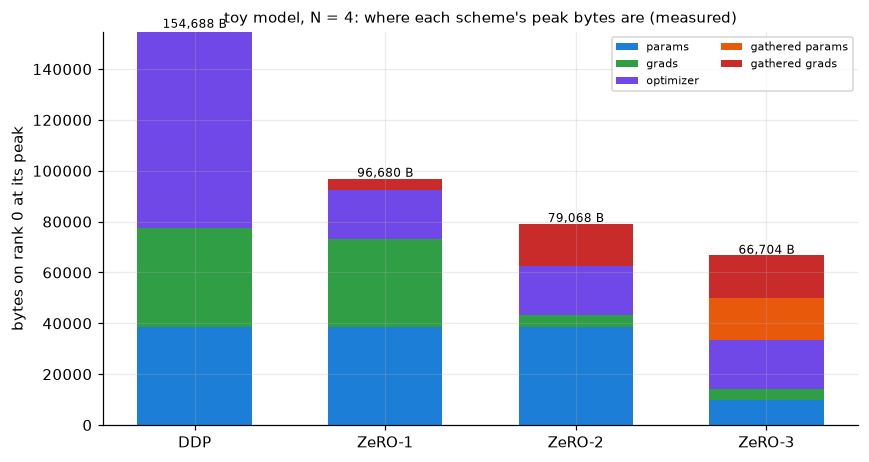

DDP     peak at: start of step
ZeRO-1  peak at: backward unit 0 (full grad)
ZeRO-2  peak at: backward unit 1 (full grad)
ZeRO-3  peak at: backward unit 1 (full grad)


In [6]:
def at_peak(tr):
    ev = last_step(tr); n, r = max(ev, key=lambda e: sum(e[1].values())); return n, r
schemes = [("DDP", ddp.tr), ("ZeRO-1", sims[1].tr), ("ZeRO-2", sims[2].tr), ("ZeRO-3", sims[3].tr)]
fig, ax = plt.subplots(figsize=(8, 4.3))
for k, (name, tr) in enumerate(schemes):
    n, r = at_peak(tr); bottom = 0
    for c in dk.Tracker.CATS:
        ax.bar(k, r[c], bottom=bottom, color=COL[c], width=0.6, label=c if k == 0 else None); bottom += r[c]
    ax.text(k, bottom * 1.01, f"{bottom:,d} B", ha="center", fontsize=8)
ax.set_xticks(range(4)); ax.set_xticklabels([s for s, _ in schemes]); ax.set_ylabel("bytes on rank 0 at its peak"); ax.legend(fontsize=7, ncol=2)
ax.set_title("toy model, N = 4: where each scheme's peak bytes are (measured)", fontsize=10); plt.tight_layout(); plt.savefig(ASSETS / "zero_stages_peak.png", dpi=110); plt.show()
for name, tr in schemes: print(f"{name:7s} peak at: {at_peak(tr)[0]}")

[FIGURE: rank 0's bytes at its own peak moment, by category. **Notice** the purple optimizer block shrinks first (ZeRO-1), the green gradient block next (ZeRO-2), and for ZeRO-3 the blue parameter block shrinks but orange/red *gathered* blocks appear: the persistent saving is partly paid back as a transient.]

On the toy, the four peaks are **154,688 / 96,680 / 79,068 / 66,704 B**. The ordering is the ordering of the paper, but the toy reductions against DDP (**1.6×, 2.0×, 2.3×**) are much smaller than the 7.5B / N = 64 arithmetic (3.8×, 7.2×, 63×) because a 9,668-parameter model on 4 ranks has proportionally large transients and a small N; the arithmetic in Section 1 is the better guide at scale, and neither includes activations. We now look at how these stages are configured in the library that made them popular.

## 5. DeepSpeed in practice

DeepSpeed (Rasley et al., 2020) is the library that shipped ZeRO. Its user interface is a JSON config. **We have not run DeepSpeed in this notebook**: it is not installed here and its stage 3 and offload paths are built for CUDA GPUs. The cell below builds the configs for the three stages as Python dicts and checks the one rule we can check without the library, that the global batch is `micro_batch × accumulation × world_size`. Key names follow the DeepSpeed documentation as we know it; check them against the version you install.

In [7]:
def ds_config(stage, world, micro=4, accum=8, offload=False):
    cfg = {"train_micro_batch_size_per_gpu": micro, "gradient_accumulation_steps": accum,
           "train_batch_size": micro * accum * world, "bf16": {"enabled": True}, "gradient_clipping": 1.0,
           "zero_optimization": {"stage": stage, "overlap_comm": True, "contiguous_gradients": True,
                                 "reduce_bucket_size": 5e8}}
    z = cfg["zero_optimization"]
    if stage >= 2: z["allgather_bucket_size"] = 5e8
    if stage == 3: z.update({"stage3_prefetch_bucket_size": 5e8, "stage3_param_persistence_threshold": 1e5, "stage3_gather_16bit_weights_on_model_save": True})
    if offload: z["offload_optimizer"] = {"device": "cpu", "pin_memory": True}
    return cfg
for st in (1, 2, 3): print(f"--- stage {st}\n" + json.dumps(ds_config(st, 64)["zero_optimization"], indent=1))
c = ds_config(3, 64)
check("DeepSpeed batch rule: train_batch_size = micro * accumulation * world_size", c["train_batch_size"] == 4 * 8 * 64, str(c["train_batch_size"]))

--- stage 1
{
 "stage": 1,
 "overlap_comm": true,
 "contiguous_gradients": true,
 "reduce_bucket_size": 500000000.0
}
--- stage 2
{
 "stage": 2,
 "overlap_comm": true,
 "contiguous_gradients": true,
 "reduce_bucket_size": 500000000.0,
 "allgather_bucket_size": 500000000.0
}
--- stage 3
{
 "stage": 3,
 "overlap_comm": true,
 "contiguous_gradients": true,
 "reduce_bucket_size": 500000000.0,
 "allgather_bucket_size": 500000000.0,
 "stage3_prefetch_bucket_size": 500000000.0,
 "stage3_param_persistence_threshold": 100000.0,
 "stage3_gather_16bit_weights_on_model_save": true
}
PASS - DeepSpeed batch rule: train_batch_size = micro * accumulation * world_size | 2048


How the knobs relate to what we built (our understanding of the documentation; verify in your version):

| DeepSpeed key | what it controls | in our simulator / FSDP |
|---|---|---|
| `zero_optimization.stage` 1 / 2 / 3 | what is sharded | `ShardSim(stage=…)` / FSDP `FULL_SHARD` ≈ 3, `SHARD_GRAD_OP` ≈ 2 |
| `reduce_bucket_size` | how many gradient elements per reduce-scatter | bucket size of Section 3 in notebook 01 |
| `overlap_comm` | run collectives on a side stream during compute | the overlap model of notebook 01 |
| `stage3_prefetch_bucket_size` | how far ahead to all-gather parameters | FSDP forward/backward prefetch |
| `stage3_param_persistence_threshold` | parameters smaller than this are not sharded | avoids 3 collectives for a tiny LayerNorm |
| `offload_optimizer.device = "cpu"` | optimizer state in CPU RAM | not simulated; see below |

**Offload, with its cost.** ZeRO-Offload (Ren et al., 2021) keeps the 12Ψ of optimizer state in CPU memory and runs Adam on the CPU, so the GPU holds 4Ψ: **28 GB for a 7B model** instead of 112 GB. In exchange, each step moves the bf16 gradients down (2Ψ = 14 GB) and updated parameters up (14 GB) over PCIe. The cell models when that transfer hides behind compute; the constants (400 TFLOP/s achieved, 25 GB/s PCIe, 4,096 tokens per micro-batch) are **assumptions, not measurements**.

In [8]:
psi, flops_rate, pcie = 7e9, 400e12, 25e9
transfer = 2 * (2 * psi) / pcie                                   # grads down + params up, bf16
print(f"GPU state without offload {16*psi/1e9:.0f} GB -> with optimizer offload {4*psi/1e9:.0f} GB")
print(f"PCIe transfer per optimizer step: {transfer:.2f} s (modelled)")
print(f"{'accumulation steps':>19s}{'compute/step (s)':>18s}{'transfer share':>16s}")
for k in (1, 2, 4, 8, 16):
    comp = k * 6 * psi * 4096 / flops_rate
    print(f"{k:19d}{comp:18.2f}{transfer / (comp + transfer):16.0%}")
check("offload keeps 4*Psi bytes on GPU (28 GB for 7B)", abs(4 * psi / 1e9 - 28) < 1e-9)

GPU state without offload 112 GB -> with optimizer offload 28 GB
PCIe transfer per optimizer step: 1.12 s (modelled)
 accumulation steps  compute/step (s)  transfer share
                  1              0.43             72%
                  2              0.86             57%
                  4              1.72             39%
                  8              3.44             25%
                 16              6.88             14%
PASS - offload keeps 4*Psi bytes on GPU (28 GB for 7B) 


In this model offload is a good trade only with enough gradient accumulation: at 1 micro-batch per step the PCIe transfer (1.12 s) is **72% of the step**, at 16 micro-batches 14%, and with perfect overlap less. It buys 4× lower GPU memory for a 7B model but turns a compute-bound step into a transfer-bound one unless the batch is large, which is why we treat it as a way to fit a model, not a way to speed training. The accumulation trick is the first of three techniques that sharding does not cover.

## 6. Activations and batch size

Sharding reduces *model state*. At large scale, **activations** (the intermediate tensors saved for backward) are the other half of the budget and are not divided by N in data parallelism, because each GPU processes its own micro-batch.

**Tiny example.** A 16-layer network, each layer saves one 64 × 512 fp32 activation (131 kB) for backward: 16 × 131 kB = **2.1 MB** per micro-batch. With **activation recomputation** (a.k.a. checkpointing, Chen et al., 2016) we save only each layer's *input* at block boundaries, which here is the same size, so we group layers: with 4 blocks of 4 layers we save 4 inputs and recompute the other activations during backward. The price is one extra forward pass: forward + backward costs 1 + 2 = 3 units of compute, and with recomputation 4, i.e. **+33%**. The cell measures both effects on a real 16-layer MLP: saved bytes are counted through PyTorch's `saved_tensors_hooks`, time with a stopwatch on this CPU.

In [9]:
from torch.autograd.graph import saved_tensors_hooks
class Block(nn.Module):
    def __init__(s, d=512, k=4):
        super().__init__(); s.net = nn.Sequential(*[m for _ in range(k) for m in (nn.Linear(d, d), nn.GELU())])
    def forward(s, x): return s.net(x)
def build(seed=0):
    torch.manual_seed(seed); return nn.ModuleList([Block() for _ in range(4)])           # 16 Linear+GELU layers
def run(blocks, x, ckpt):
    saved, seen = [0], set(); pptr = {p.data_ptr() for p in blocks.parameters()}
    def pack(t):
        if t.data_ptr() not in seen and t.data_ptr() not in pptr: seen.add(t.data_ptr()); saved[0] += t.numel() * t.element_size()
        return t
    with saved_tensors_hooks(pack, lambda t: t):
        h = x
        for b in blocks: h = checkpoint(b, h, use_reentrant=True) if ckpt else b(h)
        loss = h.pow(2).mean()
    loss.backward(); return saved[0], [p.grad.clone() for p in blocks.parameters()]
x = torch.randn(64, 512, requires_grad=True)
b0, g0 = run(build(), x, False); b1, g1 = run(build(), x, True)
gerr = max((a - b).abs().max().item() for a, b in zip(g0, g1))
def timeit(ckpt, reps=8):
    bl = build(); t = []
    for _ in range(reps): t0 = time.perf_counter(); run(bl, x, ckpt); t.append(time.perf_counter() - t0)
    return float(np.median(t[1:]))
t0_, t1_ = timeit(False), timeit(True)
print(f"saved-for-backward bytes: no recompute {b0:,d} | recompute {b1:,d} | ratio {b0/b1:.1f}x")
print(f"max gradient difference: {gerr:.1e}")
print(f"time per forward+backward: {t0_*1e3:.1f} ms -> {t1_*1e3:.1f} ms  ({t1_/t0_:.2f}x; theory 4/3 = 1.33x)")
check("recomputation gives identical gradients", gerr < 1e-6, f"{gerr:.1e}")
check("recomputation stores fewer activation bytes", b1 < 0.5 * b0, f"{b0/b1:.1f}x fewer")
check("recomputation costs extra time (1.1x - 1.7x on this CPU)", 1.1 < t1_ / t0_ < 1.7, f"{t1_/t0_:.2f}x")

saved-for-backward bytes: no recompute 4,325,376 | recompute 655,360 | ratio 6.6x
max gradient difference: 0.0e+00
time per forward+backward: 4.7 ms -> 5.6 ms  (1.19x; theory 4/3 = 1.33x)
PASS - recomputation gives identical gradients | 0.0e+00
PASS - recomputation stores fewer activation bytes | 6.6x fewer
PASS - recomputation costs extra time (1.1x - 1.7x on this CPU) | 1.19x


In our setting, recomputing at 4-layer block boundaries gives **identical gradients** and **stores 6.6× fewer activation bytes** (4,325,376 → 655,360 B) for a time overhead of **1.21×** against the theoretical 1.33× (one noisy CPU measurement). Two caveats: the saving grows with the number of layers per block, and the time overhead was measured on one CPU run, so treat 1.33× as the guide. In practice, large-scale runs mostly use selective recomputation (only the attention score memory, Korthikanti et al., 2022) because it removes most of the activation memory for a few percent of compute; we do not measure that here.

**Gradient accumulation** is the second tool: instead of one batch of 64, run four micro-batches of 16, add up their gradients (each loss divided by 4), then step once. Activation memory is that of 16 samples, and the update is the same. We check the "the same" part.

In [10]:
torch.manual_seed(0); lin = nn.Sequential(nn.Linear(16, 32), nn.Tanh(), nn.Linear(32, 4)); Xb, Yb = torch.randn(64, 16), torch.randn(64, 4)
lin.zero_grad(); ((lin(Xb) - Yb) ** 2).mean().backward(); g_big = [p.grad.clone() for p in lin.parameters()]
lin.zero_grad()
for xb, yb in zip(Xb.chunk(4), Yb.chunk(4)): (((lin(xb) - yb) ** 2).mean() / 4).backward()      # accumulates into .grad
err_acc = max((a - p.grad).abs().max().item() for a, p in zip(g_big, lin.parameters()))
print(f"max |grad(batch 64) - sum of 4 accumulated micro-batch grads| = {err_acc:.1e}")
check("gradient accumulation == one large batch", err_acc < 1e-6, f"{err_acc:.1e}")

max |grad(batch 64) - sum of 4 accumulated micro-batch grads| = 2.2e-08
PASS - gradient accumulation == one large batch | 2.2e-08


The accumulated gradient equals the large-batch gradient to **2.2e-8**. There is one interaction worth knowing: with ZeRO-2/3, accumulating over k micro-batches either reduce-scatters at every micro-batch (k× the gradient communication, minimal memory) or accumulates full gradients first (1× communication, more memory). That trade-off is the reason DeepSpeed and FSDP both expose it as a setting; we did not measure it. Sharding, recomputation and accumulation together still assume that **one layer's forward fits on one GPU and finishes quickly**. When it does not, we have to split the layers themselves.

## 7. Tensor parallelism

**Tiny example.** An MLP block computes `Y = GeLU(X·A)·B` with `A` of shape 16 × 64 and `B` of shape 64 × 16. Cut `A` into 4 **column** blocks (16 × 16 each) and `B` into 4 **row** blocks (16 × 16 each). GPU *i* computes `Z_i = GeLU(X·A_i)·B_i` entirely locally, because GeLU acts element-wise on its own columns. The true output is `Y = Z_0 + Z_1 + Z_2 + Z_3`: **one all-reduce per MLP block** in the forward pass, and a mirrored one in backward.

**General definition.** Tensor parallelism (Shoeybi et al., 2019, Megatron-LM) splits each weight matrix across T GPUs inside a layer, pairing a column-parallel matmul with a row-parallel one so that only one all-reduce of the *activations* (size batch × sequence × hidden) is needed per block. We verify the equivalence numerically, including the gradients, with T = 4 simulated GPUs.

In [11]:
torch.manual_seed(0); T, h, f = 4, 16, 64
Xt = torch.randn(8, h); A = torch.randn(h, f) / 4; B = torch.randn(f, h) / 8
# dense reference
Ad, Bd, Xd = A.clone().requires_grad_(), B.clone().requires_grad_(), Xt.clone().requires_grad_()
Yd = Fn.gelu(Xd @ Ad) @ Bd; (Yd ** 2).sum().backward()
# tensor parallel: shard i owns A[:, i-th column block] and B[i-th row block]; the python sum() is the all-reduce
As = [a.clone().requires_grad_() for a in A.chunk(T, dim=1)]; Bs = [b.clone().requires_grad_() for b in B.chunk(T, dim=0)]; Xs = [Xt.clone().requires_grad_() for _ in range(T)]
Z = [Fn.gelu(Xs[i] @ As[i]) @ Bs[i] for i in range(T)]
Ytp = sum(Z); (Ytp ** 2).sum().backward()
e_fwd = (Ytp - Yd).abs().max().item()
e_ga = max((As[i].grad - Ad.grad.chunk(T, dim=1)[i]).abs().max().item() for i in range(T))
e_gb = max((Bs[i].grad - Bd.grad.chunk(T, dim=0)[i]).abs().max().item() for i in range(T))
e_gx = (sum(x.grad for x in Xs) - Xd.grad).abs().max().item()       # backward all-reduce of dX
print(f"forward error {e_fwd:.1e} | dA shards {e_ga:.1e} | dB shards {e_gb:.1e} | dX (all-reduce) {e_gx:.1e}")
print(f"each GPU stores {As[0].numel() + Bs[0].numel()} of {A.numel() + B.numel()} weights ({1/T:.0%})")
check("tensor-parallel MLP == dense MLP (forward)", e_fwd < 1e-5)
check("tensor-parallel gradients match dense (dA, dB, dX)", max(e_ga, e_gb, e_gx) < 1e-5)

forward error 2.4e-07 | dA shards 9.5e-07 | dB shards 1.9e-06 | dX (all-reduce) 6.0e-07
each GPU stores 512 of 2048 weights (25%)
PASS - tensor-parallel MLP == dense MLP (forward) 
PASS - tensor-parallel gradients match dense (dA, dB, dX) 


The tensor-parallel block matches the dense one to **2.4e-7** in the output and **≤ 1.9e-6** in every gradient (fp32 summation order), and each GPU stores a quarter of the weights *and* does a quarter of the matmul work, which pure data parallelism never does. The cost is communication in the critical path: the all-reduce sits between two matmuls and cannot be postponed. For a GPT-style layer there are two such all-reduces per layer in forward (attention output and MLP output) and two in backward. The cell puts numbers on that for a hidden size of 8,192, 4,096 tokens per micro-batch, bf16 activations and T = 8, with **assumed** link speeds (450 GB/s inside a node, 50 GB/s between nodes).

In [12]:
hid, seq, mb, T8, L, psi64 = 8192, 4096, 1, 8, 80, 12 * 80 * 8192 ** 2
act_bytes = seq * mb * hid * 2
ar_bytes = 2 * (T8 - 1) / T8 * act_bytes                       # ring all-reduce bytes per GPU
per_layer = 4 * ar_bytes                                       # 2 forward + 2 backward
compute_s = 6 * psi64 * seq * mb / T8 / 400e12                 # per micro-batch, per TP GPU, assumed 400 TFLOP/s achieved
print(f"parameters (12*L*h^2): {psi64/1e9:.1f}B | activation tensor {act_bytes/1e6:.0f} MB | all-reduce {ar_bytes/1e6:.0f} MB/GPU | per layer {per_layer/1e6:.0f} MB")
print(f"compute per micro-batch per GPU: {compute_s*1e3:.0f} ms")
for name, bw in (("NVLink-class, 450 GB/s", 450e9), ("InfiniBand-class, 50 GB/s", 50e9)):
    t = L * per_layer / bw; print(f"TP comm at {name:26s}: {t*1e3:6.0f} ms = {t/compute_s:5.0%} of compute")
check("tensor-parallel communication is far cheaper on fast intra-node links (modelled)", L * per_layer / 450e9 < 0.25 * compute_s < L * per_layer / 50e9)

parameters (12*L*h^2): 64.4B | activation tensor 67 MB | all-reduce 117 MB/GPU | per layer 470 MB
compute per micro-batch per GPU: 495 ms
TP comm at NVLink-class, 450 GB/s    :     84 ms =   17% of compute
TP comm at InfiniBand-class, 50 GB/s :    752 ms =  152% of compute
PASS - tensor-parallel communication is far cheaper on fast intra-node links (modelled) 


In this model, tensor parallelism across 8 GPUs costs about **17% of compute time on NVLink-class links and about 150% on InfiniBand-class links** (all modelled from the stated bandwidths, with no overlap), which is why TP is used **inside a node** and why the next dimension, splitting by depth, is used *across* nodes: its communication is one activation tensor per stage boundary instead of four per layer.

## 8. Pipeline parallelism

**Tiny example.** Four GPUs (*stages*) each hold a quarter of the layers. Send one batch and stage 1 works while stages 2–4 wait, then stage 2 works while the others wait: 75% idle. Cut the batch into *m* micro-batches and the stages overlap, but the first micro-batch must still cross all four stages before the last stage can start, and at the end the first stage sits idle while the last drains. Those idle triangles are the **bubble**.

**General definition.** With p stages and m micro-batches, GPipe (Huang et al., 2019) has a bubble fraction of **(p − 1)/(m + p − 1)**. The 1F1B schedule (one forward, one backward, alternating; PipeDream, Narayanan et al., 2019) has the *same* bubble but limits the number of micro-batches whose activations are alive to p instead of m. We do not trust the formula: the cell below is a small list scheduler that places every forward and backward task (forward time 1, backward time 2) respecting dependencies, then measures idle time and in-flight activations directly.

   m   formula  GPipe bubble  1F1B bubble   GPipe in-flight/stage   1F1B in-flight/stage
   4     42.9%         42.9%        42.9%            [4, 4, 4, 4]           [4, 3, 2, 1]
   8     27.3%         27.3%        27.3%            [8, 8, 8, 8]           [4, 3, 2, 1]
  16     15.8%         15.8%        15.8%        [16, 16, 16, 16]           [4, 3, 2, 1]
  32      8.6%          8.6%         8.6%        [32, 32, 32, 32]           [4, 3, 2, 1]
PASS - simulated GPipe and 1F1B bubbles equal (p-1)/(m+p-1) 
PASS - 1F1B keeps at most p micro-batches in flight; GPipe keeps all m 


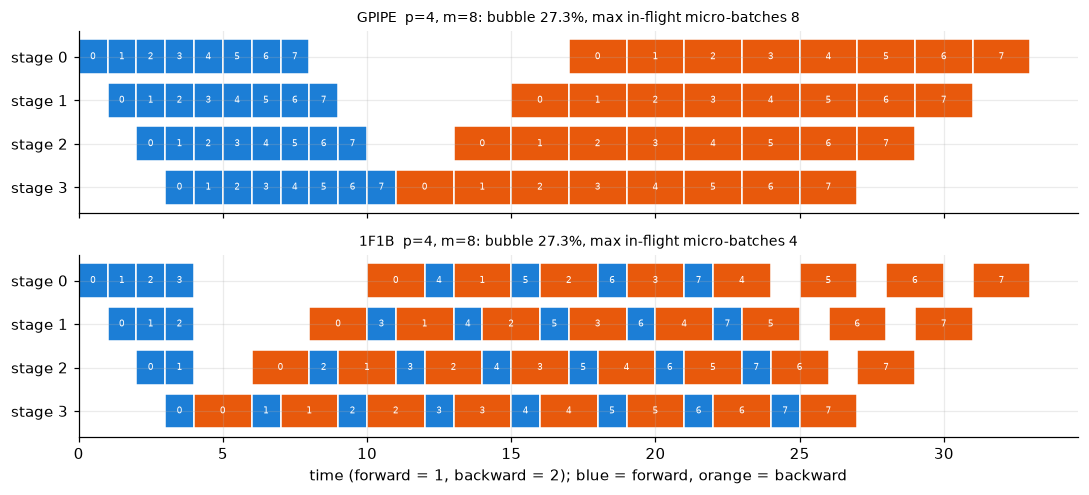

In [13]:
def pipe_schedule(p, m, kind, tf=1.0, tb=2.0):
    orders = []
    for s in range(p):
        if kind == "gpipe": ops = [("F", i) for i in range(m)] + [("B", i) for i in range(m)]
        else:
            w = min(p - s, m); ops = [("F", i) for i in range(w)]; f_, b_ = w, 0
            while b_ < m:
                ops.append(("B", b_)); b_ += 1
                if f_ < m: ops.append(("F", f_)); f_ += 1
        orders.append(ops)
    end, free, idx, tasks, done = {}, [0.0] * p, [0] * p, [], 0
    while done < 2 * p * m:
        prog = False
        for s in range(p):
            if idx[s] >= len(orders[s]): continue
            k, i = orders[s][idx[s]]
            dep = (end.get(("F", s - 1, i)) if s > 0 else 0.0) if k == "F" else (end.get(("B", s + 1, i)) if s < p - 1 else end.get(("F", s, i)))
            if dep is None: continue
            st = max(free[s], dep); d = tf if k == "F" else tb
            end[(k, s, i)] = st + d; free[s] = st + d; tasks.append((s, k, i, st, d)); idx[s] += 1; done += 1; prog = True
        assert prog, "deadlock"
    span = max(free); bubble = 1 - m * (tf + tb) / span
    inflight = []
    for s in range(p):
        ev = sorted([(t[3], 1 if t[1] == "F" else -1) for t in tasks if t[0] == s]); cur = mx = 0
        for _, dlt in ev: cur += dlt; mx = max(mx, cur)
        inflight.append(mx)
    return span, bubble, inflight, tasks

p = 4
print(f"{'m':>4s} {'formula':>9s} {'GPipe bubble':>13s} {'1F1B bubble':>12s} {'GPipe in-flight/stage':>23s} {'1F1B in-flight/stage':>22s}")
rows = []
for m in (4, 8, 16, 32):
    sg, bg, ig, _ = pipe_schedule(p, m, "gpipe"); s1, b1, i1, _ = pipe_schedule(p, m, "1f1b"); fm = (p - 1) / (m + p - 1)
    rows.append((m, fm, bg, b1, ig, i1)); print(f"{m:4d} {fm:9.1%} {bg:13.1%} {b1:12.1%} {str(ig):>23s} {str(i1):>22s}")
check("simulated GPipe and 1F1B bubbles equal (p-1)/(m+p-1)", all(abs(r[1] - r[2]) < 1e-9 and abs(r[1] - r[3]) < 1e-9 for r in rows))
check("1F1B keeps at most p micro-batches in flight; GPipe keeps all m", all(max(r[5]) <= p for r in rows) and all(max(r[4]) == r[0] for r in rows))

fig, axs = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True); m = 8
for ax, kind in zip(axs, ("gpipe", "1f1b")):
    span, bub, infl, tasks = pipe_schedule(p, m, kind)
    for s, k, i, st, d in tasks:
        ax.barh(p - 1 - s, d, left=st, color="#1c7ed6" if k == "F" else "#e8590c", edgecolor="white"); ax.text(st + d / 2, p - 1 - s, str(i), ha="center", va="center", fontsize=6, color="white")
    ax.set_yticks(range(p)); ax.set_yticklabels([f"stage {s}" for s in reversed(range(p))]); ax.set_title(f"{kind.upper()}  p={p}, m={m}: bubble {bub:.1%}, max in-flight micro-batches {max(infl)}", fontsize=9)
axs[1].set_xlabel("time (forward = 1, backward = 2); blue = forward, orange = backward"); plt.tight_layout(); plt.savefig(ASSETS / "pipeline_schedules.png", dpi=110); plt.show()

[FIGURE: pipeline schedules for p = 4 stages and m = 8 micro-batches; numbers inside bars are micro-batch indices. **Notice** the two schedules have the same empty triangles (the bubble) but GPipe holds all 8 micro-batches' activations at its middle point while 1F1B alternates and never holds more than 4.]

The simulation reproduces the closed form exactly (**42.9%, 27.3%, 15.8% and 8.6%** for m = 4, 8, 16, 32 at p = 4) and confirms the 1F1B memory advantage: at most 4 micro-batches in flight against GPipe's m. The cost of reducing the bubble is more micro-batches per step, i.e. a larger global batch or smaller micro-batches that use the GPU less efficiently; there is no free setting. Interleaved schedules (Narayanan et al., 2021) shrink the bubble further at the cost of more communication; we did not implement them here. We now have all the pieces and can ask which combination to run.

## 9. Combining them

A "configuration" for N GPUs is a triple (dp, tp, pp) with dp·tp·pp = N, plus a ZeRO stage for the data-parallel group. Each axis buys something and costs something:

| axis | divides | cost | where it should live |
|---|---|---|---|
| ZeRO / FSDP over dp | optimizer, grads, (params) | up to 1.5× DP communication | any interconnect, overlappable |
| tensor parallel (tp) | every weight and its matmul | 4 activation all-reduces per layer, not overlappable | inside a node |
| pipeline parallel (pp) | layers (depth) | bubble (pp−1)/(m+pp−1), p2p activations | across nodes |

**The question we ask:** a GPT-style model with L = 80, h = 8,192, so Ψ = 12·L·h² ≈ **64.4B** parameters, trained on 64 GPUs with 80 GB each, sequence length 4,096, micro-batch 1, 32 micro-batches per step, bf16 with Adam, full activation recomputation. Which (dp, tp, pp, ZeRO) fit? The cell enumerates them with formulas from the previous sections. Everything here is **modelled arithmetic**, with the activation term deliberately rough (stored layer inputs plus one layer's working set).

In [14]:
Ngpu, hid, seq, mb, L, m_micro = 64, 8192, 4096, 1, 80, 32
psi = 12 * L * hid ** 2; HBM = 80.0; NV = 450e9
def config_row(dp, tp, pp, z):
    q = psi / (tp * pp)                                           # parameters held per GPU before ZeRO
    state = {0: 16 * q, 1: 4 * q + 12 * q / dp, 3: 16 * q / dp}[z]
    layers_local = L / pp; inflight = pp if pp > 1 else 1
    act = layers_local * seq * mb * hid * 2 * inflight + 34 * seq * mb * hid / tp          # stored inputs + one layer working set
    gpu_gb = (state + act) / 1e9
    bubble = (pp - 1) / (m_micro + pp - 1)
    tokens = seq * mb; compute = 6 * psi * tokens / (tp * pp) / 400e12
    tp_comm = 0.0 if tp == 1 else 4 * layers_local * 2 * (tp - 1) / tp * seq * mb * hid * 2 / (NV if tp <= 8 else 50e9) / compute
    dp_bytes = (2 if z < 3 else 3) * (dp - 1) / dp * 2 * q / 1e9
    return dict(dp=dp, tp=tp, pp=pp, z=z, state=state / 1e9, act=act / 1e9, gpu=gpu_gb, fits=gpu_gb < HBM, bubble=bubble, tp_comm=tp_comm, dp_gb=dp_bytes)
rows = []
for tp, pp in itertools.product((1, 2, 4, 8), (1, 2, 4, 8, 16)):
    if Ngpu % (tp * pp): continue
    dp = Ngpu // (tp * pp)
    for z in (0, 1, 3): rows.append(config_row(dp, tp, pp, z))
feas = [r for r in rows if r["fits"]]
print(f"{len(rows)} configurations, {len(feas)} fit in {HBM:.0f} GB;  Psi = {psi/1e9:.1f}B")
print(f"\n{'dp':>3s}{'tp':>3s}{'pp':>3s}{'ZeRO':>5s}{'state GB':>9s}{'act GB':>7s}{'total':>7s}{'bubble':>8s}{'TP comm':>9s}{'DP GB/step':>11s}")
def show(rs):
    for r in rs: print(f"{r['dp']:3d}{r['tp']:3d}{r['pp']:3d}{r['z']:5d}{r['state']:9.1f}{r['act']:7.1f}{r['gpu']:7.1f}{r['bubble']:8.1%}{r['tp_comm']:9.0%}{r['dp_gb']:11.1f}")
print("-- pure data parallelism:"); show([r for r in rows if r["tp"] == 1 and r["pp"] == 1])
cost = lambda r: r["bubble"] + r["tp_comm"]                        # crude overhead score: idle fraction + exposed TP fraction
best = sorted(feas, key=cost)[:6]; print("-- feasible, lowest (bubble + TP comm) overhead:"); show(best)
pure = {r["z"]: r["fits"] for r in rows if r["tp"] == 1 and r["pp"] == 1}
check("pure data parallelism: DDP and ZeRO-1 do not fit 80 GB, ZeRO-3 does (modelled)", (not pure[0]) and (not pure[1]) and pure[3], str(pure))

57 configurations, 41 fit in 80 GB;  Psi = 64.4B

 dp tp pp ZeRO state GB act GB  total  bubble  TP comm DP GB/step
-- pure data parallelism:
 64  1  1    0   1030.8    6.5 1037.3    0.0%       0%      253.7
 64  1  1    1    269.8    6.5  276.3    0.0%       0%      253.7
 64  1  1    3     16.1    6.5   22.6    0.0%       0%      380.5
-- feasible, lowest (bubble + TP comm) overhead:
 64  1  1    3     16.1    6.5   22.6    0.0%       0%      380.5
 32  2  1    3     16.1    5.9   22.0    0.0%       2%      187.2
 32  1  2    3     16.1    6.5   22.6    3.0%       0%      187.2
 16  2  2    3     16.1    5.9   22.0    3.0%       2%       90.6
 16  4  1    3     16.1    5.7   21.8    0.0%       7%       90.6
 16  1  4    3     16.1    6.5   22.6    8.6%       0%       90.6
PASS - pure data parallelism: DDP and ZeRO-1 do not fit 80 GB, ZeRO-3 does (modelled) | {0: False, 1: False, 3: True}


Reading the table, three results stand out in this model. **First**, a 64B model does not fit under DDP (1,031 GB) or ZeRO-1 (270 GB) on 64 GPUs without splitting layers: the 4Ψ of parameters and gradients alone is about 258 GB. **Second**, ZeRO-3 fits at every parallel layout (16 GB of state), including pure data parallelism, so our overhead score ranks pure ZeRO-3 first by construction (zero bubble, zero TP cost). The last column is the catch: it moves **380 GB per GPU per step across all 64 GPUs**, against 91 GB for dp = 16, and on a real cluster much of that crosses the slow inter-node network, which this model does not price. **Third**, we therefore do *not* claim that the table reproduces the usual large-run recipe (tensor parallelism inside a node, pipeline parallelism across nodes, ZeRO over the rest; e.g. Narayanan et al., 2021): it shows that several layouts fit, and what each pays in bubble, TP communication and DP bytes. Choosing among them needs measured throughput, with inter-node bandwidth in the model.

The final cell does the one calculation that sets the scale of the whole enterprise: training FLOPs, using the standard approximation of **6 × Ψ × tokens** (Kaplan et al., 2020).

In [15]:
tokens = 1.4e12; flops = 6 * psi * tokens
for g, mfu in ((64, 0.40), (1024, 0.40), (1024, 0.25)):
    sec = flops / (g * 989e12 * mfu)          # 989 TFLOP/s = dense bf16 peak of an H100 SXM (vendor figure); mfu = fraction achieved (assumed)
    print(f"{g:5d} GPUs, MFU {mfu:.0%}: {sec/86400:7.0f} days for {tokens/1e12:.1f}T tokens  ({flops:.2e} FLOPs)")
check("6*Psi*D training FLOPs for 64.4B params on 1.4T tokens is ~5.4e23", abs(flops / 5.4e23 - 1) < 0.02, f"{flops:.2e}")

   64 GPUs, MFU 40%:     247 days for 1.4T tokens  (5.41e+23 FLOPs)
 1024 GPUs, MFU 40%:      15 days for 1.4T tokens  (5.41e+23 FLOPs)
 1024 GPUs, MFU 25%:      25 days for 1.4T tokens  (5.41e+23 FLOPs)
PASS - 6*Psi*D training FLOPs for 64.4B params on 1.4T tokens is ~5.4e23 | 5.41e+23


In this model, a 64B-parameter model on 1.4T tokens is **5.4 × 10²³ FLOPs**: about **247 days on 64 GPUs at an assumed 40% MFU** (*model FLOPs utilisation*, the fraction of peak the hardware sustains), **15 days on 1,024 GPUs at 40% and 25 days at 25%**, which is why the efficiency of every item above matters in percentage points. The peak figure (989 TFLOP/s dense bf16 for an H100 SXM) is a vendor number and the 25–40% MFU range is an assumption; achieved values depend on everything we have not modelled.

## Closing thoughts

The sequence we followed is also the historical one: data parallelism with all-reduce, then the observation that its replicated state is redundant (ZeRO, Rajbhandari et al., 2020; shipped in DeepSpeed, Rasley et al., 2020; and as FSDP in PyTorch, Zhao et al., 2023), alongside tensor parallelism (Shoeybi et al., 2019) and pipeline parallelism (Huang et al., 2019; Narayanan et al., 2019) that were developed for models whose layers were already too big. What we did **not** do, and what we consider open: measure any of this on GPUs with NCCL and real interconnects; interleaved pipeline schedules; sequence/context parallelism for long sequences; expert parallelism for mixture-of-experts models; ZeRO-Infinity-style NVMe offload; fault tolerance and checkpointing at thousands of GPUs, where failures rather than FLOPs often set the schedule. The configuration search in Section 9 is a sketch for ranking options, and should be replaced by measured throughput before anyone commits a cluster to it.

In [16]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n, ok, d) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n}")
failed = [n for n, ok, _ in CHECKS if not ok]
print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed"); assert not failed, failed

 #  status  check
 1  PASS    reproduces the ZeRO paper's 7.5B / N=64 example: 120, 31.4, 16.6, 1.9 GB
 2  PASS    ZeRO-1 saving approaches 4x for large N
 3  PASS    ZeRO-1 final weights == single-process training (<1e-5)
 4  PASS    ZeRO-2 final weights == single-process training (<1e-5)
 5  PASS    ZeRO-3 final weights == single-process training (<1e-5)
 6  PASS    ZeRO-1 and ZeRO-2 send exactly DDP's bytes per step
 7  PASS    ZeRO-3 sends 1.5x DDP's bytes per step
 8  PASS    peak memory per rank: DDP > ZeRO-1 > ZeRO-2 > ZeRO-3
 9  PASS    ZeRO-2 peak is below ZeRO-1 at identical communication
10  PASS    DeepSpeed batch rule: train_batch_size = micro * accumulation * world_size
11  PASS    offload keeps 4*Psi bytes on GPU (28 GB for 7B)
12  PASS    recomputation gives identical gradients
13  PASS    recomputation stores fewer activation bytes
14  PASS    recomputation costs extra time (1.1x - 1.7x on this CPU)
15  PASS    gradient accumulation == one large batch
16  PASS    tenso

## Exercises
- In Section 2, change `N` to 8 (use `dk.make_data(8)`) and check whether ZeRO-1's saving over DDP grows. What limits it?
- In Section 6, change the block size from 4 layers to 2 and to 8. How do saved bytes and runtime move? Which block size would you pick for 80 layers?
- In Section 8, add `tf=1, tb=1` (equal forward and backward times) and confirm the bubble formula still holds. Why does it not depend on the ratio?
- In Section 9, change the sequence length to 32,768. Which configurations stop fitting first, and why?
- Add expert parallelism to the table of axes: what would it divide, and what collective would it need?

## Honest limits
Measured: tiny models on a Mac CPU with simulated ranks (real tensors, counted bytes), real PyTorch activation recomputation and tensor-parallel gradients on small tensors, and a deterministic pipeline scheduler. **Not run:** DeepSpeed (not installed here), any GPU or NCCL code, ZeRO-Offload, interleaved pipelines, selective recomputation. **Modelled** with assumed constants: PCIe offload timing, tensor-parallel communication times, the 64B configuration table, and the training-time estimate. The configuration search ranks by a crude overhead sum and ignores inter-node bandwidth for data parallelism, kernel efficiency, memory fragmentation and framework overheads.